In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import coint, adfuller
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from statsmodels.tsa.api import VAR

In [2]:
# Load and preprocess data
file_path = r'D:\MG\！CUHKSZ\~！大二 下\UBS瑞银 商赛\data\BYD&Tesla.xlsx'
df = pd.read_excel(
    file_path,
    header=0,
    skiprows=[0],
    index_col='日期',
    parse_dates=['日期'],
    date_parser=lambda x: pd.to_datetime(x, format='%Y-%m-%d')
)
df = df[["比亚迪股份", "特斯拉(TESLA)"]].dropna()

C:\Users\19927\AppData\Local\Temp\ipykernel_48912\2444998763.py:3: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  df = pd.read_excel(


In [3]:
# Normalize price series (base=100)
security = df["比亚迪股份"].div(df["比亚迪股份"].iloc[0])
candidate = df["特斯拉(TESLA)"].div(df["特斯拉(TESLA)"].iloc[0])

# Calculate spread
spread = candidate - security

In [4]:
# Heuristic metrics
X = np.column_stack([np.ones(len(spread)), np.arange(1, len(spread)+1)])
drift_coef = np.linalg.inv(X.T @ X) @ X.T @ spread
drift = abs(drift_coef[1])
volatility = spread.std()
corr_price = candidate.corr(security)
corr_ret = candidate.pct_change().corr(security.pct_change())

In [5]:
# Engle-Granger Test
t_stat1, p_value1, _ = coint(security, candidate, trend='c')
t_stat2, p_value2, _ = coint(candidate, security, trend='c')
eg_p = min(p_value1, p_value2)
eg_sig = eg_p < 0.05

In [7]:
# Johansen Test
data = pd.DataFrame({"BYD": security, "TSLA": candidate})
var_model = VAR(data)
lag_order_results = var_model.select_order()
lag_order = lag_order_results.selected_orders['aic']
result = coint_johansen(data, det_order=0, k_ar_diff=lag_order)
trace0, trace1 = result.lr1[0], result.lr1[1]
trace0_cv, trace1_cv = 15.4943, 3.8415  # 95% critical values
trace_sig = (trace0 > trace0_cv) & (trace1 > trace1_cv)

d:\MG\Python\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


In [8]:
# Results
print(f"""
Cointegration Analysis: BYD vs. TESLA (2020-03-31 to 2025-04-17)
===============================================================
1. Engle-Granger Test:
   - Min p-value: {eg_p:.4f}
   - Significant (95% CI): {eg_sig}

2. Johansen Test:
   - Trace Statistic (Rank 0): {trace0:.2f} > {trace0_cv} → {trace0 > trace0_cv}
   - Trace Statistic (Rank 1): {trace1:.2f} > {trace1_cv} → {trace1 > trace1_cv}
   - Joint Significance: {trace_sig}

Heuristic Metrics:
===============================================================
- Drift (Abs. Trend Coefficient): {drift:.4f}
- Spread Volatility: {volatility:.4f}
- Price Correlation: {corr_price:.2f}
- Return Correlation: {corr_ret:.2f}
""")


Cointegration Analysis: BYD vs. TESLA (2020-03-31 to 2025-04-17)
1. Engle-Granger Test:
   - Min p-value: 0.0200
   - Significant (95% CI): True

2. Johansen Test:
   - Trace Statistic (Rank 0): 13.99 > 15.4943 → False
   - Trace Statistic (Rank 1): 4.46 > 3.8415 → True
   - Joint Significance: False

Heuristic Metrics:
- Drift (Abs. Trend Coefficient): 0.0004
- Spread Volatility: 1.5465
- Price Correlation: 0.73
- Return Correlation: 0.10



C:\Users\19927\AppData\Local\Temp\ipykernel_48912\3450937409.py:5: UserWarning: Glyph 26085 (\N{CJK UNIFIED IDEOGRAPH-65E5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\19927\AppData\Local\Temp\ipykernel_48912\3450937409.py:5: UserWarning: Glyph 26399 (\N{CJK UNIFIED IDEOGRAPH-671F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


<Figure size 1400x600 with 0 Axes>

C:\Users\19927\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26085 (\N{CJK UNIFIED IDEOGRAPH-65E5}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\19927\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26399 (\N{CJK UNIFIED IDEOGRAPH-671F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


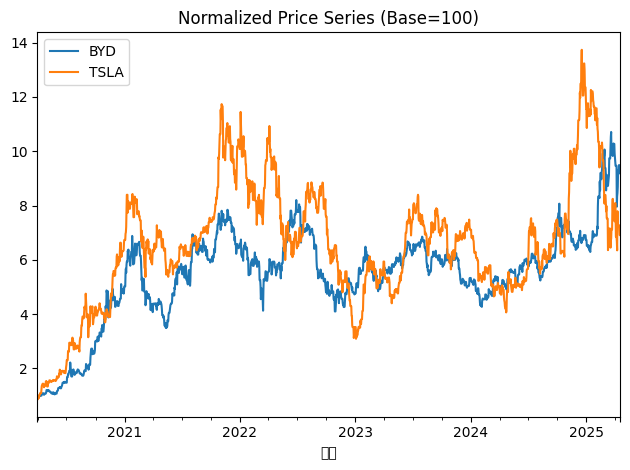

C:\Users\19927\AppData\Local\Temp\ipykernel_48912\3450937409.py:11: UserWarning: Glyph 26085 (\N{CJK UNIFIED IDEOGRAPH-65E5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\19927\AppData\Local\Temp\ipykernel_48912\3450937409.py:11: UserWarning: Glyph 26399 (\N{CJK UNIFIED IDEOGRAPH-671F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\19927\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26085 (\N{CJK UNIFIED IDEOGRAPH-65E5}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\19927\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26399 (\N{CJK UNIFIED IDEOGRAPH-671F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


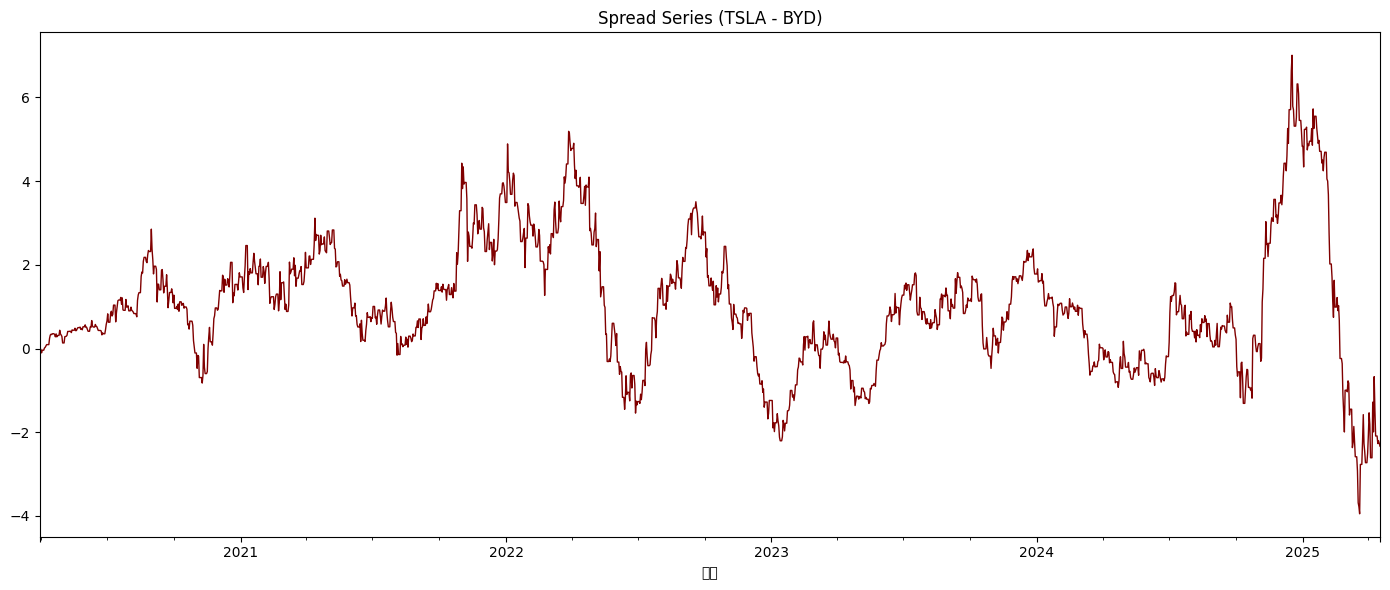

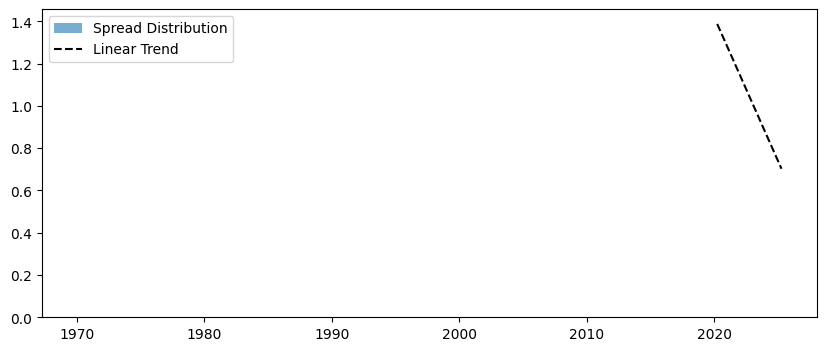

In [10]:
# Visualization
# Plot 1: Normalized Price Series
plt.figure(figsize=(14, 6))
data.plot(title="Normalized Price Series (Base=100)")
plt.tight_layout()
plt.show()

# Plot 2: Spread Series
plt.figure(figsize=(14, 6))
spread.plot(title="Spread Series (TSLA - BYD)", c='maroon', lw=1)
plt.tight_layout()
plt.show()

# Plot 3: Spread Distribution
plt.figure(figsize=(10, 4))
plt.hist(spread, bins=30, density=True, alpha=0.6, label='Spread Distribution')
plt.plot(spread.index, X @ drift_coef, ls='--', c='k', label='Linear Trend')
plt.legend()
plt.show()